# Notebook 04 — Artificial Neural Networks and Regression with TensorFlow

**Level:** Beginner to Intermediate  
**Track:** Deep Learning with TensorFlow  
**Main tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib, and Scikit-learn

---

## Notebook Overview

In this notebook, we build neural networks for **regression**: predicting a continuous numerical value from one or more input features. We will move from a simple baseline to a multilayer perceptron (MLP), train the models with Keras, compare regression loss functions, and inspect prediction errors using residual analysis.

The dataset is synthetic and is designed for teaching. It is not real patient, clinical, or gene-expression data. Synthetic data lets us control the data-generating process and focus on the modeling workflow without making biological claims.

> **Notation:** Inline mathematics uses `$...$`; display equations use `$$...$$`. All equations are written in notebook-compatible Markdown.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Distinguish regression from classification and define features, targets, and predictions.
2. Establish a simple baseline before training a neural network.
3. Split data into training, validation, and test sets without leakage.
4. Explain the role of input normalization in an MLP.
5. Design a feedforward neural network for a continuous target.
6. Explain why a regression output layer is usually linear.
7. Compare Mean Squared Error (MSE), Mean Absolute Error (MAE), and Huber loss.
8. Train and monitor a Keras model using `fit()` and callbacks.
9. Evaluate regression performance with appropriate metrics.
10. Use residual plots to identify patterns that a single metric can hide.

## Notebook Roadmap

| Section | Topic |
|---|---|
| 1 | Regression as a supervised learning problem |
| 2 | Creating and exploring a synthetic regression dataset |
| 3 | Training, validation, and test sets |
| 4 | Feature normalization and data leakage |
| 5 | MLP architecture for regression |
| 6 | Regression loss functions and evaluation metrics |
| 7 | Building and training Keras models |
| 8 | Prediction, evaluation, and residual analysis |
| 9 | Baseline and loss-function comparisons |
| 10 | Common mistakes, exercises, and references |

### Prerequisites

- Basic Python and NumPy
- DataFrames and plotting with Pandas and Matplotlib
- Tensors, `tf.data`, Keras models, and automatic differentiation from Notebooks 01–03
- Basic matrix operations and derivatives from Notebook 02

## 1. Regression as a Supervised Learning Problem

### 1.1 What Is Regression?

Regression is a supervised learning task in which a model learns to predict a **continuous target** from input features. Examples include predicting a measured temperature, house price, material strength, or a quantitative laboratory measurement.

In this notebook:

- **Features** (`X`) are the input variables available to the model.
- **Target** (`y`) is the continuous value we want to predict.
- **Prediction** (`y_hat`) is the value estimated by the model.
- **Residual** is the difference between an observed target and its prediction.

For a dataset with $N$ observations and $d$ features, the input matrix has shape $N \times d$ and the target commonly has shape $N \times 1$.

### 1.2 A Function-Learning View

A regression model learns a function that maps features to a numerical prediction:

$$
\hat{y} = f_{\theta}(\mathbf{x})
$$

where:

- $\mathbf{x}$ is an input feature vector,
- $f$ is the model architecture,
- $\theta$ represents all trainable parameters (weights and biases),
- $\hat{y}$ is the model prediction.

Training adjusts $\theta$ to reduce a loss function over the training examples. The objective is not to memorize the training set; it is to learn a relationship that generalizes to unseen observations.

### 1.3 Regression Versus Classification

| Property | Regression | Classification |
|---|---|---|
| Target | Continuous value | Discrete class or label |
| Example | Predict a numeric measurement | Predict benign vs. malignant |
| Typical output | One or more real-valued numbers | Class score(s) or probabilities |
| Common loss | MSE, MAE, Huber | Cross-entropy |
| Common metrics | MAE, RMSE, $R^2$ | Accuracy, precision, recall, AUC |

The distinction comes from the prediction target and the task definition, not from whether the input data are images, tabular measurements, or sequences.

### 1.4 A First Baseline: Predict the Training-Set Mean

Before using a complex model, build a simple baseline. A mean baseline predicts the average target value observed in the training set for every new observation:

$$
\hat{y}_{\text{baseline}} = \bar{y}_{\text{train}}
$$

A useful model should improve on this baseline on data that were not used to fit the model. The baseline must be calculated from the training set only; using the full dataset would leak information from the validation or test sets.

In [1]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__ if hasattr(keras, "__version__") else "Bundled with TensorFlow")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1
NumPy version: 2.4.6
Pandas version: 2.3.3


## 2. Create and Explore a Synthetic Regression Dataset

### 2.1 Why Use Synthetic Data?

Synthetic data are useful for learning because we know how the target was generated. We can deliberately include linear and nonlinear relationships, noise, and a small number of unusual observations. This makes the exercise reproducible and helps us study model behavior.

The four input features below are generic numerical variables. Their names do not imply that they are validated biological measurements.

In [2]:
RANDOM_SEED = 42
N_SAMPLES = 1_200

keras.utils.set_random_seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)

feature_1 = rng.normal(loc=0.0, scale=1.0, size=N_SAMPLES)
feature_2 = rng.uniform(low=0.0, high=100.0, size=N_SAMPLES)
feature_3 = rng.normal(loc=10.0, scale=3.0, size=N_SAMPLES)
feature_4 = rng.uniform(low=-2.0, high=2.0, size=N_SAMPLES)

# A nonlinear data-generating relationship with observation noise.
noise = rng.normal(loc=0.0, scale=1.2, size=N_SAMPLES)
target = (
    2.5 * feature_1
    - 0.035 * feature_2
    + 0.65 * np.square(feature_3 - 10.0)
    + 1.4 * np.sin(1.5 * feature_4)
    + 0.8 * feature_1 * feature_4
    + noise
)

# Add a small number of deliberately contaminated observations for the robust-loss experiment.
outlier_mask = rng.random(N_SAMPLES) < 0.025
target[outlier_mask] += rng.normal(loc=0.0, scale=9.0, size=outlier_mask.sum())

FEATURE_COLUMNS = ["feature_1", "feature_2", "feature_3", "feature_4"]
df = pd.DataFrame(
    {
        "feature_1": feature_1,
        "feature_2": feature_2,
        "feature_3": feature_3,
        "feature_4": feature_4,
        "target": target,
    }
)

print("Dataset shape:", df.shape)
print("Number of deliberately contaminated targets:", int(outlier_mask.sum()))
df.head()

Dataset shape: (1200, 5)
Number of deliberately contaminated targets: 31


,feature_1,feature_2,feature_3,feature_4,target
0,0.304717,20.698516,5.173580,0.443298,14.435151
1,-1.039984,42.273403,12.005666,-0.814981,0.039291
2,0.750451,17.613830,13.369284,-0.616598,6.419707
3,0.940565,13.469202,9.865014,1.162694,4.347595
4,-1.951035,86.028189,4.117463,1.513259,14.339103


### 2.2 Inspect the Data

Start with data types, missing values, summary statistics, and feature distributions. In a real project, this step should also include checks for duplicated records, impossible values, measurement units, and the meaning of every variable.

In [3]:
print("Data types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nSummary statistics:")
display(df.describe().T)

Data types:
 feature_1    float64
feature_2    float64
feature_3    float64
feature_4    float64
target       float64
dtype: object

Missing values:
 feature_1    0
feature_2    0
feature_3    0
feature_4    0
target       0
dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
feature_1,1200.0,-0.022238,0.985594,-3.648413,-0.682160,0.003452,0.615437,3.178854
feature_2,1200.0,49.907807,29.171450,0.056813,24.663185,48.265720,75.972401,99.976534
feature_3,1200.0,10.096882,2.970722,1.415445,8.042600,10.066729,12.196262,19.265537
feature_4,1200.0,-0.053543,1.139084,-1.996296,-1.029038,-0.085138,0.912215,1.996160
target,1200.0,3.963691,8.593576,-12.198628,-1.574139,1.959680,7.082492,60.282311


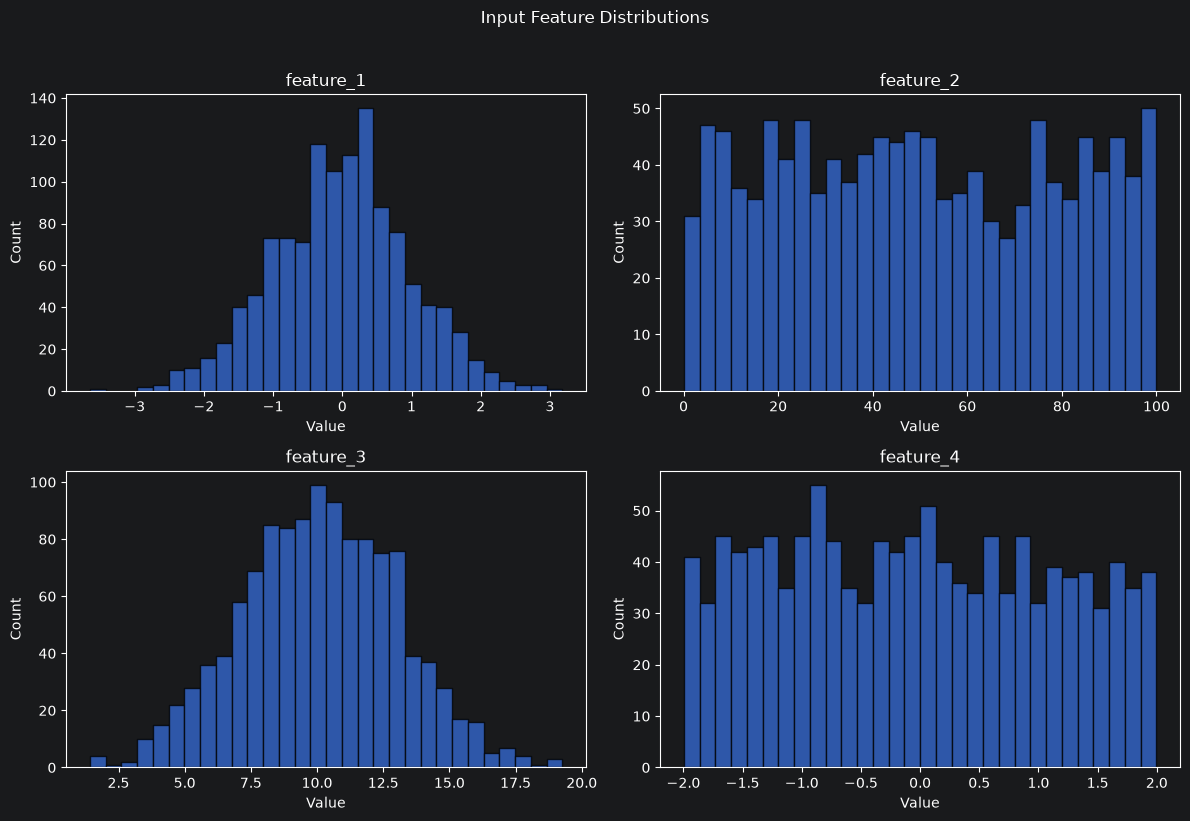

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.ravel(), FEATURE_COLUMNS):
    ax.hist(df[column], bins=30, edgecolor="black", alpha=0.75)
    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
fig.suptitle("Input Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

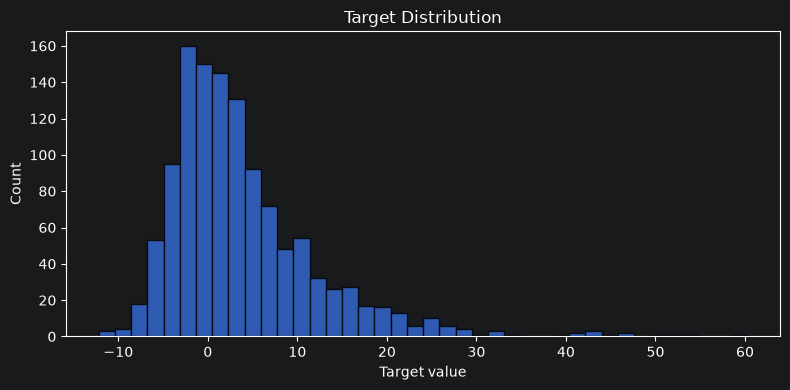

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["target"], bins=40, edgecolor="black", alpha=0.8)
ax.set_title("Target Distribution")
ax.set_xlabel("Target value")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

### 2.3 Inspect Feature–Target Relationships

A scatter plot can reveal whether a feature has a roughly linear, nonlinear, weak, or noisy association with the target. With multiple inputs, a two-dimensional plot cannot show the complete relationship, but it is still useful for exploratory analysis.

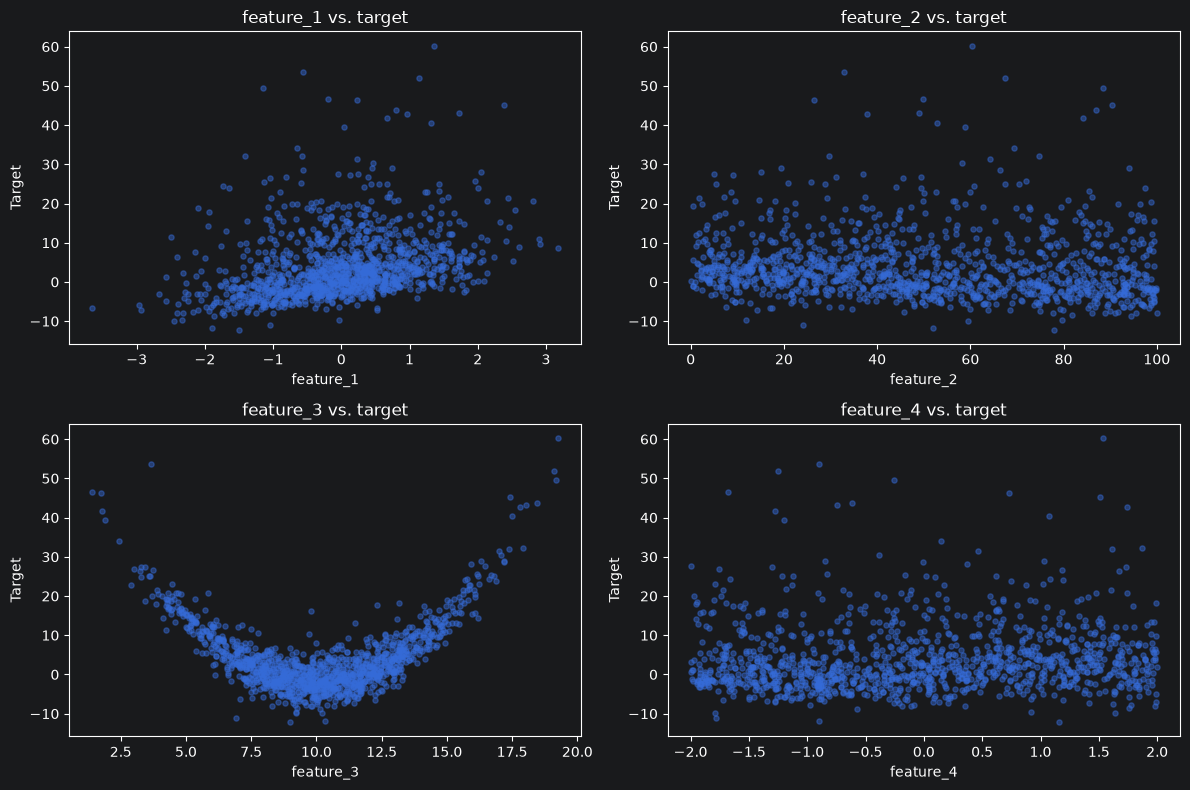

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.ravel(), FEATURE_COLUMNS):
    ax.scatter(df[column], df["target"], s=14, alpha=0.45)
    ax.set_title(f"{column} vs. target")
    ax.set_xlabel(column)
    ax.set_ylabel("Target")
plt.tight_layout()
plt.show()

## 3. Split the Data Before Model Fitting

### 3.1 Training, Validation, and Test Sets

We use three disjoint subsets for different purposes:

- **Training set:** used to update the model's trainable parameters.
- **Validation set:** used during development to monitor generalization, compare configurations, and guide decisions such as early stopping.
- **Test set:** held back until the final evaluation to estimate performance on unseen observations.

A common split for a small teaching dataset is 64% training, 16% validation, and 20% test. The exact proportions depend on dataset size and the study design.

### 3.2 Separate Features and Target

The target is kept as a two-dimensional array with shape $(N, 1)$. This aligns with a Keras regression output layer containing one unit and avoids accidental shape mismatches during training and evaluation.

In [7]:
X = df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y = df[["target"]].to_numpy(dtype=np.float32)

print("X shape:", X.shape)
print("y shape:", y.shape)
assert X.ndim == 2 and y.ndim == 2
assert X.shape[0] == y.shape[0]

X shape: (1200, 4)
y shape: (1200, 1)


### 3.3 Create the Three Splits

First, reserve 20% for testing. Then split the remaining 80% so that 20% of that portion becomes validation data. This produces 64% training, 16% validation, and 20% test overall.

In [8]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=RANDOM_SEED
)

split_summary = pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "observations": [len(X_train), len(X_val), len(X_test)],
        "percentage": [
            100 * len(X_train) / len(X),
            100 * len(X_val) / len(X),
            100 * len(X_test) / len(X),
        ],
    }
)
display(split_summary)

,split,observations,percentage
0,train,768,64.0
1,validation,192,16.0
2,test,240,20.0


### 3.4 What Is Data Leakage?

Data leakage occurs when information that would not legitimately be available at prediction time influences model fitting or model selection. A common example is fitting a scaler on the full dataset before splitting it. This allows information from validation and test observations to influence preprocessing parameters.

**Correct rule:** split first; fit preprocessing transformations using training data only; then apply the fitted transformation to validation and test data.

In clinical or biomedical prediction, splitting may also need to happen at the patient, subject, family, site, or time level. Random row-wise splitting can be invalid when multiple rows come from the same subject or when the task predicts future observations.

## 4. Feature Normalization

### 4.1 Why Normalize Input Features?

Our synthetic input features have different numerical ranges. A feature measured on a much larger scale can dominate numerical calculations and make optimization less well-conditioned. Standardization transforms each feature using a mean and standard deviation:

$$
z = \frac{x - \mu}{\sigma}
$$

where $\mu$ and $\sigma$ are estimated from the training data. After standardization, a feature has approximately zero mean and unit standard deviation on the data used to estimate those statistics.

### 4.2 Use a Keras Normalization Layer

A Keras `Normalization` layer stores the statistics learned by `adapt()`. We call `adapt()` with **training features only**. The layer can then be included inside the model so that the same transformation is applied consistently during training and inference.

In [9]:
normalizer = keras.layers.Normalization(axis=-1, name="feature_normalization")
normalizer.adapt(X_train)

print("Learned normalization mean:", normalizer.mean.numpy())
print("Learned normalization variance:", normalizer.variance.numpy())

Learned normalization mean: [[-3.936257e-02  4.869166e+01  1.005758e+01 -2.975958e-02]]
Learned normalization variance: [[  0.9385616 853.0883      8.983284    1.2961797]]


In [10]:
X_train_normalized = normalizer(X_train).numpy()
X_val_normalized = normalizer(X_val).numpy()

normalization_check = pd.DataFrame(
    {
        "feature": FEATURE_COLUMNS,
        "train_mean_after_normalization": X_train_normalized.mean(axis=0),
        "train_std_after_normalization": X_train_normalized.std(axis=0),
        "validation_mean_after_normalization": X_val_normalized.mean(axis=0),
    }
)
display(normalization_check)

,feature,train_mean_after_normalization,train_std_after_normalization,validation_mean_after_normalization
0,feature_1,-4.501393e-09,1.0,0.045437
1,feature_2,-8.906548e-07,1.0,0.149517
2,feature_3,1.083439e-07,1.0,0.001261
3,feature_4,-2.235174e-08,1.0,-0.015529


> **Important:** The validation-set means do not need to be exactly zero, and its standard deviations do not need to be exactly one. The normalization statistics were estimated from training data and then applied unchanged to validation and test data.

## 5. Designing a Multilayer Perceptron for Regression

### 5.1 What Is an MLP?

A multilayer perceptron is a feedforward neural network made of an input representation, one or more hidden layers, and an output layer. Each Dense layer computes an affine transformation followed by an optional activation function.

For one Dense layer:

$$
\mathbf{h} = \phi(\mathbf{W}\mathbf{x} + \mathbf{b})
$$

where $\mathbf{W}$ is a weight matrix, $\mathbf{b}$ is a bias vector, and $\phi$ is an activation function.

### 5.2 Choosing the Output Layer

For a single-target regression problem with an unrestricted real-valued target, a common output layer is:

```python
keras.layers.Dense(1, activation="linear")
```

A linear activation returns the affine output without restricting it to a range such as $[0, 1]$. In Keras, `activation=None` is equivalent to a linear activation. A bounded output activation may be appropriate when the target has a genuine known range and the modeling choice is justified by the task.

For multiple continuous targets, the output layer usually has one unit per target variable.

### 5.3 Count Trainable Parameters

For a Dense layer with $n_{in}$ input units and $n_{out}$ output units, the weight matrix has $n_{in}n_{out}$ parameters and the bias vector has $n_{out}$ parameters:

$$
P = n_{in}n_{out} + n_{out} = (n_{in}+1)n_{out}
$$

For a network with layer widths $d \rightarrow n_1 \rightarrow n_2 \rightarrow q$:

$$
P = (d+1)n_1 + (n_1+1)n_2 + (n_2+1)q
$$

This count describes trainable Dense-layer parameters; it does not count non-trainable normalization statistics.

In [11]:
def dense_parameter_count(n_in, n_out):
    """Return the number of weights and biases in a Dense layer."""
    return (n_in + 1) * n_out

input_width = len(FEATURE_COLUMNS)
hidden_1 = 64
hidden_2 = 32
output_width = 1

parameter_breakdown = {
    "input_to_hidden_1": dense_parameter_count(input_width, hidden_1),
    "hidden_1_to_hidden_2": dense_parameter_count(hidden_1, hidden_2),
    "hidden_2_to_output": dense_parameter_count(hidden_2, output_width),
}
print(parameter_breakdown)
print("Total Dense parameters:", sum(parameter_breakdown.values()))

{'input_to_hidden_1': 320, 'hidden_1_to_hidden_2': 2080, 'hidden_2_to_output': 33}
Total Dense parameters: 2433


### 5.4 A Practical Starting Architecture

We will begin with two hidden Dense layers:

- Input: four numerical features
- Hidden layer 1: 64 units with ReLU
- Hidden layer 2: 32 units with ReLU
- Output: one unit with a linear activation

This is a teaching architecture, not a universally optimal configuration. The number of units and layers should be justified through validation experiments rather than chosen because larger networks are assumed to be better.

In [12]:
def build_mlp(hidden_units=(64, 32), loss="mse", learning_rate=1e-3, seed=RANDOM_SEED):
    """Build a regression MLP with a normalization layer adapted on training data."""
    keras.utils.set_random_seed(seed)

    feature_normalizer = keras.layers.Normalization(axis=-1, name="feature_normalization")
    feature_normalizer.adapt(X_train)

    model_layers = [keras.Input(shape=(X_train.shape[1],), name="features"), feature_normalizer]
    for index, units in enumerate(hidden_units, start=1):
        model_layers.append(
            keras.layers.Dense(units, activation="relu", name=f"hidden_{index}")
        )
    model_layers.append(keras.layers.Dense(1, activation="linear", name="regression_output"))

    model = keras.Sequential(model_layers, name="regression_mlp")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=loss,
        metrics=[
            keras.metrics.MeanAbsoluteError(name="mae"),
            keras.metrics.RootMeanSquaredError(name="rmse"),
        ],
    )
    return model

model = build_mlp()
model.summary()

Model: "regression_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ feature_normalization           │ (None, 4)              │             9 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regression_output (Dense)       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,442 (9.54 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 9 (40.00 B)

### 5.5 Check the Model's Input and Output Shapes

The model expects a batch with shape `(batch_size, number_of_features)`. Its output should have shape `(batch_size, 1)` for one continuous target. Checking shapes early helps prevent silent broadcasting errors or incorrectly aligned targets.

In [13]:
example_batch = tf.convert_to_tensor(X_train[:5], dtype=tf.float32)
example_predictions = model(example_batch)

print("Input batch shape:", example_batch.shape)
print("Prediction shape:", example_predictions.shape)
assert example_predictions.shape == (5, 1)

Input batch shape: (5, 4)
Prediction shape: (5, 1)


## 6. Regression Loss Functions and Evaluation Metrics

A **loss function** quantifies the error used by the optimizer during training. An **evaluation metric** summarizes model performance in a form that is easier to interpret. A metric may also be used during training for monitoring, but it does not automatically contribute to parameter updates.

### 6.1 Mean Squared Error (MSE)

Mean Squared Error averages the squared residuals:

$$
\operatorname{MSE} = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

MSE penalizes large residuals more strongly because the error is squared. It is differentiable everywhere and is widely used for regression. Its value is expressed in squared target units, which can make direct interpretation less intuitive.

### 6.2 Mean Absolute Error (MAE)

Mean Absolute Error averages the absolute residuals:

$$
\operatorname{MAE} = \frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|
$$

MAE is expressed in the same units as the target and is less sensitive to a small number of very large residuals than MSE. The absolute-value function is not differentiable at zero, although subgradients make MAE usable in gradient-based optimization.

### 6.3 Root Mean Squared Error (RMSE)

RMSE is the square root of MSE:

$$
\operatorname{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}
$$

RMSE is expressed in the target's units. Like MSE, it gives relatively more influence to large errors.

### 6.4 Huber Loss

Huber loss combines a quadratic penalty for small residuals with a linear penalty for large residuals. For residual $e=y-\hat{y}$ and threshold $\delta>0$:

$$
L_{\delta}(e)=
\begin{cases}
\frac{1}{2}e^2, & |e|\leq\delta \\
\delta\left(|e|-\frac{1}{2}\delta\right), & |e|>\delta
\end{cases}
$$

Huber loss can be less sensitive to extreme residuals than MSE while remaining smooth around zero. Its behavior depends on the threshold $\delta$ and the scale of the target. It is not automatically the best choice for every dataset.

### 6.5 The Coefficient of Determination ($R^2$)

The coefficient of determination compares residual sum of squares with the total variation around the observed mean:

$$
R^2 = 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2}
$$

An $R^2$ of 1 indicates perfect predictions on the evaluated observations. An $R^2$ of 0 corresponds to the mean-prediction reference under the usual definition. A negative value means the model performs worse than that reference on the evaluated set. $R^2$ is not a percentage of predictions that are correct.

### 6.6 Which Metric Should We Use?

| Measure | Main interpretation | Sensitivity to large errors | Units |
|---|---|---|---|
| MSE | Average squared error | High | Squared target units |
| MAE | Average absolute error | Lower than MSE | Target units |
| RMSE | Square root of average squared error | High | Target units |
| $R^2$ | Relative fit versus mean baseline | Based on squared errors | Unitless |

Metric choice should reflect the cost of prediction errors in the application. For example, under-prediction and over-prediction may have different consequences, in which case a symmetric metric may not capture the full problem.

In [14]:
# A small numerical example to compare the three point-wise error measures.
y_true_example = np.array([2.0, 3.0, 5.0, 8.0])
y_pred_example = np.array([2.5, 2.0, 5.5, 12.0])

example_mse = mean_squared_error(y_true_example, y_pred_example)
example_mae = mean_absolute_error(y_true_example, y_pred_example)
example_rmse = np.sqrt(example_mse)

print(f"MSE : {example_mse:.3f}")
print(f"MAE : {example_mae:.3f}")
print(f"RMSE: {example_rmse:.3f}")

MSE : 4.375
MAE : 1.500
RMSE: 2.092


## 7. Train a Neural Network with Keras

### 7.1 Compile the Model

For the first MLP, we will use:

- **Optimizer:** Adam with an initial learning rate of $10^{-3}$.
- **Loss:** MSE.
- **Monitoring metrics:** MAE and RMSE.

The optimizer minimizes the loss. MAE and RMSE are included to make the training history more interpretable in the target's units.

### 7.2 Configure Callbacks

Callbacks allow us to respond to training progress:

- `EarlyStopping` stops training when validation loss stops improving and can restore the best weights.
- `ReduceLROnPlateau` lowers the learning rate when validation loss has stopped improving.

The validation set is used to monitor training. The test set is not passed to `fit()` and is not used for callback decisions.

In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=18,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-5,
        verbose=1,
    ),
]

### 7.3 Fit the MLP

`model.fit()` performs the training loop. The model sees the training data in mini-batches and calculates validation metrics at the end of each epoch. We set `shuffle=True` for the training examples; this is appropriate for this independently sampled synthetic dataset.

In [16]:
EPOCHS = 150
BATCH_SIZE = 32

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 90.4240 - mae: 6.0430 - rmse: 9.5092 - val_loss: 56.2229 - val_mae: 5.4207 - val_rmse: 7.4982 - learning_rate: 0.0010
Epoch 2/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 83.3424 - mae: 5.7967 - rmse: 9.1292 - val_loss: 50.5389 - val_mae: 5.1967 - val_rmse: 7.1091 - learning_rate: 0.0010
Epoch 3/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 74.9855 - mae: 5.5279 - rmse: 8.6594 - val_loss: 43.9648 - val_mae: 4.9051 - val_rmse: 6.6306 - learning_rate: 0.0010
Epoch 4/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 66.0077 - mae: 5.3109 - rmse: 8.1245 - val_loss: 37.9396 - val_mae: 4.7060 - val_rmse: 6.1595 - learning_rate: 0.0010
Epoch 5/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 58.2112 - mae: 5.1662 - rmse: 7.6296 - val_loss: 33.2703 - val_mae: 4.5335 - val_rmse: 5.7680 - learning_rate: 0.0010
Epoch 6/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 51.3294 - mae: 4.9733 - rmse: 7.1645 - val_loss: 28.766

### 7.4 Inspect the Training History

Keras returns a `History` object. Its `history` dictionary stores the loss and metric values recorded for each epoch. The exact number of completed epochs may be smaller than the maximum because of early stopping.

In [17]:
history_df = pd.DataFrame(history.history)
history_df.tail()

,loss,mae,rmse,val_loss,val_mae,val_rmse,learning_rate
105,3.832986,1.197720,1.957801,3.615080,1.301112,1.901336,0.000250
106,3.831242,1.197221,1.957356,3.614089,1.300933,1.901076,0.000250
107,3.826590,1.196735,1.956167,3.613755,1.300840,1.900988,0.000250
108,3.816279,1.194774,1.953530,3.612031,1.300666,1.900534,0.000125
109,3.814867,1.194323,1.953169,3.611200,1.300696,1.900316,0.000125


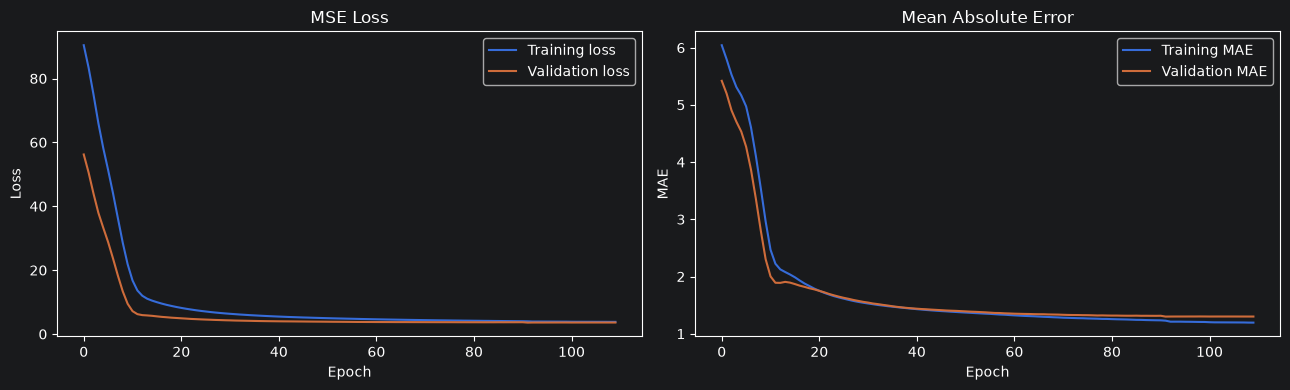

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("MSE Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["mae"], label="Training MAE")
axes[1].plot(history.history["val_mae"], label="Validation MAE")
axes[1].set_title("Mean Absolute Error")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE")
axes[1].legend()

plt.tight_layout()
plt.show()

### 7.5 Interpret Learning Curves

Look for the relationship between training and validation curves:

- If both remain high, the model may be underfitting or the optimization may be ineffective.
- If training loss continues to decrease while validation loss increases, overfitting may be occurring.
- If both decrease and then stabilize at similar levels, training may have reached a useful solution.

These patterns are diagnostic clues, not definitive proof. Dataset size, noise, the split strategy, and the chosen metric all affect the curves.

## 8. Predict and Evaluate the Model

### 8.1 Generate Predictions

The test set has not been used for fitting or model selection. We now use it for a final evaluation. For a single-output regression model, reshape the predictions into a one-dimensional array for plotting and metric functions.

In [19]:
y_pred = model.predict(X_test, verbose=0).reshape(-1)
y_test_flat = y_test.reshape(-1)

print("Number of test predictions:", len(y_pred))
print("First five observed values:", y_test_flat[:5])
print("First five predictions:", y_pred[:5])

Number of test predictions: 240
First five observed values: [11.2596035  3.28758    7.081489  -3.2153664  0.7761477]
First five predictions: [11.84105     3.0315301   7.2111387  -2.7337773  -0.20122099]


### 8.2 Calculate Test Metrics

We report MAE, MSE, RMSE, and $R^2$. Always interpret these values in the context of the target's scale, the baseline performance, and the consequences of prediction errors.

In [20]:
test_metrics = {
    "MAE": mean_absolute_error(y_test_flat, y_pred),
    "MSE": mean_squared_error(y_test_flat, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test_flat, y_pred)),
    "R2": r2_score(y_test_flat, y_pred),
}

test_metrics_df = pd.DataFrame(
    {"metric": list(test_metrics.keys()), "value": list(test_metrics.values())}
)
display(test_metrics_df)

,metric,value
0,MAE,1.344497
1,MSE,3.681185
2,RMSE,1.918642
3,R2,0.956863


### 8.3 Observed Versus Predicted Values

A useful regression diagnostic is a scatter plot of observed values against predictions. The diagonal line represents perfect agreement ($\hat{y}=y$). Points farther from the diagonal have larger prediction errors.

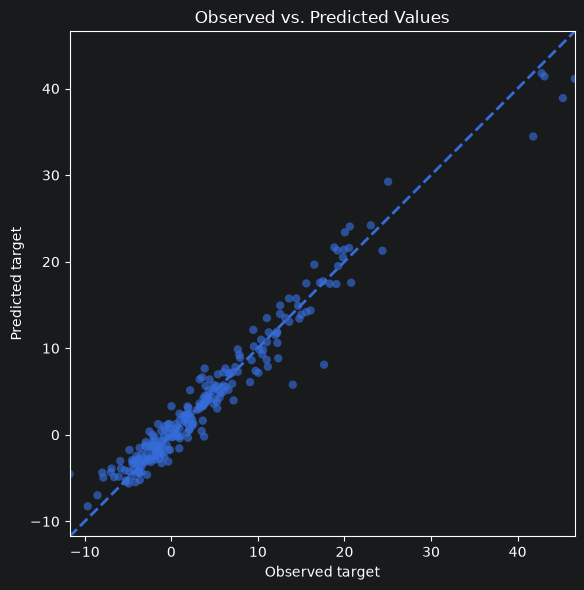

In [21]:
plot_min = min(y_test_flat.min(), y_pred.min())
plot_max = max(y_test_flat.max(), y_pred.max())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test_flat, y_pred, alpha=0.65, edgecolor="none")
ax.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--", linewidth=2)
ax.set_title("Observed vs. Predicted Values")
ax.set_xlabel("Observed target")
ax.set_ylabel("Predicted target")
ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

### 8.4 Calculate Residuals

For observation $i$, define the residual as:

$$
e_i = y_i - \hat{y}_i
$$

A positive residual means the model under-predicted that observation. A negative residual means it over-predicted. Residuals are useful for checking systematic errors that aggregate metrics can conceal.

In [22]:
residuals = y_test_flat - y_pred

print(f"Mean residual: {residuals.mean():.4f}")
print(f"Residual standard deviation: {residuals.std(ddof=1):.4f}")

Mean residual: -0.0472
Residual standard deviation: 1.9221


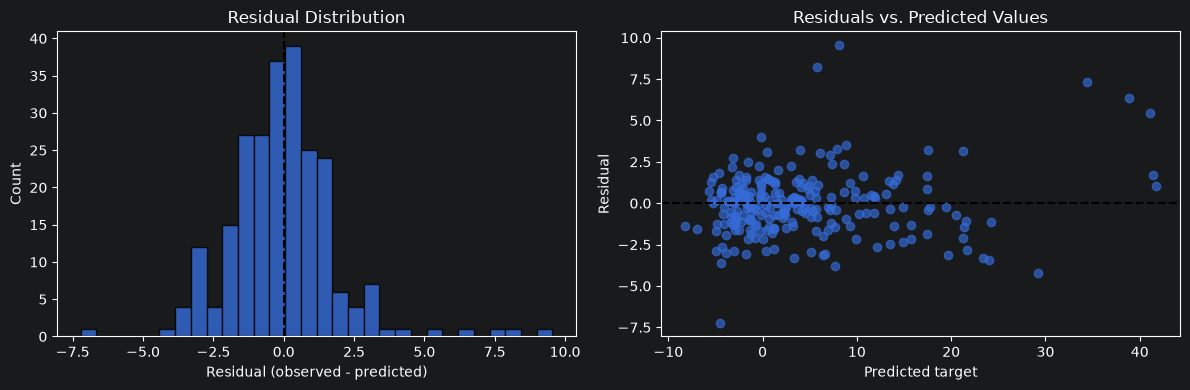

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(residuals, bins=30, edgecolor="black", alpha=0.8)
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Residual (observed - predicted)")
axes[0].set_ylabel("Count")

axes[1].scatter(y_pred, residuals, alpha=0.65)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted target")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

### 8.5 What to Look for in Residual Plots

A strong regression model should not leave obvious systematic structure in its residuals, although the exact expectations depend on the task.

- **Non-zero mean:** may indicate systematic under-prediction or over-prediction.
- **Curved pattern:** may indicate that the model has not captured a nonlinear relationship.
- **Funnel-shaped spread:** may indicate non-constant error variance (heteroscedasticity).
- **Clusters or bands:** may indicate subgroups, omitted variables, or data-generation structure.
- **Extreme residuals:** may reflect unusual observations, data errors, or limitations of the model.

Residual analysis does not prove that a model is valid. It is one part of a broader evaluation process.

## 9. Compare Against Simpler Baselines

### 9.1 Why Compare Models?

A neural network should not be selected solely because it is more complex. We compare it with:

1. A mean baseline (`DummyRegressor`), which ignores all features.
2. Linear regression, which models an additive linear relationship.
3. The MLP, which can represent nonlinear relationships through hidden layers and activation functions.

All models use the same train/test observations. The linear model is fit only on training data; the test set is used only for evaluation.

In [24]:
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train.reshape(-1))
dummy_pred = dummy_model.predict(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train.reshape(-1))
linear_pred = linear_model.predict(X_test)


def regression_metrics(y_true, y_prediction):
    return {
        "MAE": mean_absolute_error(y_true, y_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_prediction)),
        "R2": r2_score(y_true, y_prediction),
    }

comparison_rows = []
for name, prediction in [
    ("Mean baseline", dummy_pred),
    ("Linear regression", linear_pred),
    ("Neural network MLP", y_pred),
]:
    row = {"model": name}
    row.update(regression_metrics(y_test_flat, prediction))
    comparison_rows.append(row)

baseline_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE")
display(baseline_comparison)

,model,MAE,RMSE,R2
2,Neural network MLP,1.344497,1.918642,0.956863
1,Linear regression,6.062009,8.566279,0.140097
0,Mean baseline,6.613073,9.238272,-0.000108


### 9.2 Interpret the Baseline Comparison

A nonlinear MLP may outperform a linear model when the data contain nonlinear relationships and enough representative training observations. However, if the MLP does not meaningfully improve validation and test performance, a simpler model may be preferable because it is easier to interpret and maintain.

Do not use the test set repeatedly to tune the architecture. Use validation data for model development, then report the test result for the selected approach.

## 10. Compare Regression Loss Functions

### 10.1 A Controlled Comparison

The synthetic target contains a small number of deliberately contaminated observations. This gives us a setting in which to compare MSE, MAE, and Huber loss.

For a fair educational comparison, we keep the data split and network architecture fixed. We train a separate model for each loss function. The comparison is illustrative: the preferred loss depends on the target scale, noise distribution, and error costs in the real application.

In [25]:
loss_factories = {
    "MSE": lambda: keras.losses.MeanSquaredError(),
    "MAE": lambda: keras.losses.MeanAbsoluteError(),
    "Huber": lambda: keras.losses.Huber(delta=1.0),
}

loss_comparison_rows = []
loss_comparison_histories = {}

for loss_name, loss_factory in loss_factories.items():
    comparison_model = build_mlp(hidden_units=(64, 32), loss=loss_factory(), seed=RANDOM_SEED)
    comparison_history = comparison_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=12, restore_best_weights=True, verbose=0
            )
        ],
        verbose=0,
    )
    loss_comparison_histories[loss_name] = comparison_history.history
    comparison_prediction = comparison_model.predict(X_test, verbose=0).reshape(-1)

    row = {"loss": loss_name}
    row.update(regression_metrics(y_test_flat, comparison_prediction))
    loss_comparison_rows.append(row)

loss_comparison_df = pd.DataFrame(loss_comparison_rows).sort_values("RMSE")
display(loss_comparison_df)

,loss,MAE,RMSE,R2
2,Huber,1.327183,1.908351,0.957324
0,MSE,1.365681,1.930584,0.956324
1,MAE,1.352019,1.968809,0.954577


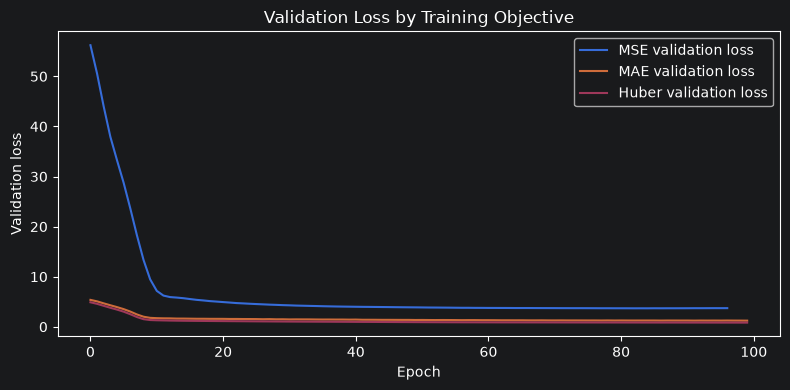

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
for loss_name, loss_history in loss_comparison_histories.items():
    ax.plot(loss_history["val_loss"], label=f"{loss_name} validation loss")
ax.set_title("Validation Loss by Training Objective")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss")
ax.legend()
plt.tight_layout()
plt.show()

### 10.2 Important Interpretation Notes

- The numerical scales of MSE, MAE, and Huber loss differ; compare each loss curve with the same loss function rather than comparing raw loss values across different objectives.
- Compare models using common evaluation metrics such as MAE and RMSE on the same test observations.
- A robust loss may reduce the influence of extreme residuals, but it may also behave differently for ordinary observations.
- If the target has a very large or very small scale, review the choice of Huber threshold and whether target scaling is appropriate.

## 11. Common Regression Modeling Mistakes

1. **Using a classification output for an unrestricted continuous target.** A sigmoid or softmax output may impose an unjustified range or probability interpretation.
2. **Fitting preprocessing on all observations.** Learn normalization statistics from training data only.
3. **Using the test set during model development.** Keep the test set out of architecture selection and callback monitoring.
4. **Comparing models on different splits.** Use identical evaluation observations for a fair comparison.
5. **Reporting only $R^2$.** Include error metrics in meaningful target units.
6. **Ignoring residual patterns.** A good average score can hide systematic errors or subgroup failures.
7. **Assuming a larger network is always better.** Model complexity should be justified by validation performance and the task.
8. **Ignoring the data structure.** In repeated-measurement or multi-site data, split at an appropriate subject, group, site, or time level.
9. **Confusing loss with metric.** The loss drives optimization; metrics help monitor and interpret performance.

## 12. Exercises

Complete these exercises after running the notebook from top to bottom.

### Exercise 1 — Architecture Capacity

1. Change the hidden-layer configuration from `(64, 32)` to `(32,)`.
2. Calculate the number of Dense parameters before building the model.
3. Compare training and validation curves.
4. Explain whether the smaller model appears to underfit, overfit, or perform similarly.

### Exercise 2 — Output Layer

1. Keep the same data and architecture.
2. Build one model with a linear output and another with a ReLU output.
3. Compare their predictions, especially for targets below zero.
4. Explain when a non-negative output constraint would be appropriate.

### Exercise 3 — Loss Function

1. Repeat the loss comparison with Huber `delta=0.5` and `delta=2.0`.
2. Compare MAE and RMSE on the same test observations.
3. Explain why the loss with the smallest training value is not necessarily the best evaluation choice.

### Exercise 4 — Residual Analysis

1. Plot residuals against each input feature.
2. Look for curvature, changing variance, or clusters.
3. State one limitation of using residual plots with a small test set.

### Exercise 5 — Reproducible Experiment

1. Run the notebook twice with the same random seed.
2. Record the test metrics and the number of epochs completed.
3. Change the seed and repeat.
4. Explain why a single random split is not sufficient evidence of robust generalization.

### Exercise 6 — Improve the Data Pipeline

Modify the split strategy to reflect a hypothetical dataset in which multiple rows belong to the same subject. Explain why rows from one subject should not appear in both training and test sets when the goal is generalization to unseen subjects.

## 13. Key Takeaways

- Regression predicts continuous numerical targets.
- Always establish a simple baseline before choosing a complex neural network.
- Separate training, validation, and test data before fitting preprocessing transformations.
- A Keras `Normalization` layer can be adapted on training inputs and embedded in the model.
- For an unrestricted single-value regression target, a linear output is a common default.
- MSE, MAE, and Huber loss penalize prediction errors differently.
- MAE and RMSE are expressed in the target's units; $R^2$ is a relative fit statistic and can be negative.
- Training curves, observed-versus-predicted plots, and residual analysis provide complementary information.
- The MLP should be compared with simpler baselines on the same held-out observations.
- Data splitting must reflect the real deployment setting, especially for grouped, longitudinal, or multi-site data.

## 14. References and Further Reading

1. TensorFlow. **Basic regression: Predict fuel efficiency.**  
   https://www.tensorflow.org/tutorials/keras/regression
2. Keras. **The Sequential model.**  
   https://keras.io/guides/sequential_model/
3. Keras. **Training with built-in methods (`fit`, `evaluate`, and `predict`).**  
   https://keras.io/guides/training_with_built_in_methods/
4. Keras API. **Losses.**  
   https://keras.io/api/losses/
5. Keras API. **Normalization layer.**  
   https://keras.io/api/layers/preprocessing_layers/numerical/normalization/
6. Scikit-learn. **Model evaluation: regression metrics.**  
   https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics
7. Scikit-learn. **Common pitfalls and recommended practices.**  
   https://scikit-learn.org/stable/common_pitfalls.html

---

## Next Notebook

**Notebook 05 — Neural Network Classification with TensorFlow**  
We will move from continuous targets to binary classification, probability outputs, decision thresholds, confusion matrices, and classification metrics.